# 10 · Loss landscapes and optimizers: learning-rate schedules, saddle points, gradient clipping

**Lecture:** *Loss Landscapes & Optimizers* (27-08-2026) · **Notes:** `../notes/10_loss_landscapes_and_optimizers.md`

The update rule is always **W ← W − η·∂L/∂W**. This lecture is about the three things that go wrong with it, and their fixes:

| Problem | Fix |
|---|---|
| the **step size η** is too big or too small, or right at the start but wrong later | **learning-rate schedules** |
| the gradient is ≈ 0 somewhere that **isn't** the answer (saddle points, flat regions, local minima) | **momentum, Adam, mini-batch noise** |
| the **gradient** suddenly becomes huge (exploding gradients) | **gradient clipping** |

In this notebook you will see each one happen, and each fix work. Runs in about 1 minute on a CPU.

In [1]:
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
torch.manual_seed(0)

## 1 · The learning rate: too small, good, too large

The simplest possible landscape: **L(w) = w²** (a bowl with its bottom at w = 0). Its gradient is 2w, so one step is w ← w − η·2w = **(1 − 2η)·w**. Start at w = 5 and take 20 steps with different η.

η = 0.01 (too small)               w after 20 steps =  3.338
η = 0.3 (good)                     w after 20 steps =  5.498e-08
η = 0.9 (too large: oscillates)    w after 20 steps =  0.05765
η = 1.05 (diverges)                w after 20 steps =  33.64


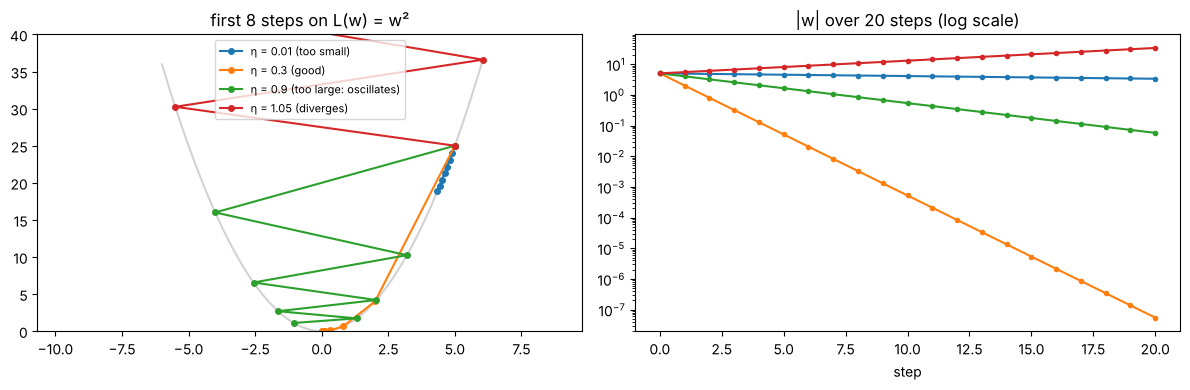

In [2]:
def descend(eta, w0=5.0, steps=20):
    ws = [w0]
    for _ in range(steps):
        ws.append(ws[-1] - eta * 2 * ws[-1])
    return np.array(ws)

etas = {"η = 0.01 (too small)": 0.01, "η = 0.3 (good)": 0.3, "η = 0.9 (too large: oscillates)": 0.9, "η = 1.05 (diverges)": 1.05}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
wgrid = np.linspace(-6, 6, 200)
axes[0].plot(wgrid, wgrid ** 2, color="lightgrey")
for name, eta in etas.items():
    ws = descend(eta)
    axes[0].plot(ws[:8], ws[:8] ** 2, "o-", ms=4, label=name)
    axes[1].semilogy(np.abs(ws) + 1e-12, "o-", ms=3, label=name)
    print(f"{name:<34} w after 20 steps = {ws[-1]: .4g}")
axes[0].set_ylim(0, 40); axes[0].set_title("first 8 steps on L(w) = w²"); axes[0].legend(fontsize=8)
axes[1].set_title("|w| over 20 steps (log scale)"); axes[1].set_xlabel("step")
plt.tight_layout(); plt.show()

- **η = 0.01:** each step multiplies w by 0.98, so after 20 steps it has barely moved (still ≈ 3.3): **stable but extremely slow**.
- **η = 0.3:** multiplies by 0.4 each step: at the bottom in a few steps.
- **η = 0.9:** multiplies by −0.8, so it **jumps over the valley** each time, bouncing from side to side (oscillation) while slowly closing in.
- **η = 1.05:** multiplies by −1.1, so each jump is **bigger** than the last: the loss **explodes**. In a real network this ends in `inf` and then `NaN`.

> On this bowl the boundary is exact: any η > 1 diverges. Real networks have no such simple formula, which is why η is tuned and scheduled.

## 2 · Learning-rate schedules

Idea: **big steps while far from a good solution, small steps once close**. PyTorch has each schedule built in (`torch.optim.lr_scheduler`). We print and plot what each one does to η.

In [3]:
def lr_trace(make_sched, epochs=30, lr0=0.01, metric=None):
    p = torch.zeros(1, requires_grad=True)
    opt = torch.optim.SGD([p], lr=lr0)
    sched = make_sched(opt)
    lrs = []
    for epoch in range(epochs):
        lrs.append(opt.param_groups[0]["lr"])
        opt.step()
        sched.step(metric[epoch]) if metric is not None else sched.step()
    return lrs

S = torch.optim.lr_scheduler
step_lrs = lr_trace(lambda o: S.StepLR(o, step_size=10, gamma=0.1))
exp_lrs = lr_trace(lambda o: S.ExponentialLR(o, gamma=0.9))
cos_lrs = lr_trace(lambda o: S.CosineAnnealingLR(o, T_max=30, eta_min=0.0001))
warm_lrs = lr_trace(lambda o: S.SequentialLR(o, [S.LinearLR(o, start_factor=0.1, total_iters=4),
                                                  S.CosineAnnealingLR(o, T_max=26, eta_min=0.0001)], milestones=[4]))
print("step decay   epochs 1, 10, 11, 20, 21, 30:", [round(step_lrs[i], 6) for i in [0, 9, 10, 19, 20, 29]])
print("exponential  epochs 1-5:", [round(v, 5) for v in exp_lrs[:5]], " epoch 30:", round(exp_lrs[29], 6))
print("cosine       epochs 1, 8, 15, 23, 30:", [round(cos_lrs[i], 5) for i in [0, 7, 14, 22, 29]])
print("warm-up      epochs 1-5:", [round(v, 5) for v in warm_lrs[:5]])

step decay   epochs 1, 10, 11, 20, 21, 30: [0.01, 0.01, 0.001, 0.001, 0.0001, 0.0001]
exponential  epochs 1-5: [0.01, 0.009, 0.0081, 0.00729, 0.00656]  epoch 30: 0.000471
cosine       epochs 1, 8, 15, 23, 30: [0.01, 0.00873, 0.00557, 0.00174, 0.00013]
warm-up      epochs 1-5: [0.001, 0.00325, 0.0055, 0.00775, 0.01]


### ReduceLROnPlateau: react to the validation loss
The lecture's validation losses: 0.40, 0.32, 0.27, 0.25, 0.25, 0.25, 0.25. With `patience=2`, the scheduler **tolerates** 2 epochs without improvement; the 3rd one triggers a cut (here ×0.1). Note that "0.25 again" counts as **no improvement**.

In [4]:
val_losses = [0.40, 0.32, 0.27, 0.25, 0.25, 0.25, 0.25, 0.25, 0.25, 0.25]
p = torch.zeros(1, requires_grad=True); opt = torch.optim.SGD([p], lr=0.01)
plateau = S.ReduceLROnPlateau(opt, mode="min", factor=0.1, patience=2)
plateau_lrs = []
for epoch, v in enumerate(val_losses, 1):
    plateau.step(v)
    plateau_lrs.append(opt.param_groups[0]["lr"])
    print(f"epoch {epoch:>2}: val loss {v:.2f} -> learning rate for next epoch {opt.param_groups[0]['lr']:.4g}")

epoch  1: val loss 0.40 -> learning rate for next epoch 0.01
epoch  2: val loss 0.32 -> learning rate for next epoch 0.01
epoch  3: val loss 0.27 -> learning rate for next epoch 0.01
epoch  4: val loss 0.25 -> learning rate for next epoch 0.01
epoch  5: val loss 0.25 -> learning rate for next epoch 0.01
epoch  6: val loss 0.25 -> learning rate for next epoch 0.01
epoch  7: val loss 0.25 -> learning rate for next epoch 0.001
epoch  8: val loss 0.25 -> learning rate for next epoch 0.001
epoch  9: val loss 0.25 -> learning rate for next epoch 0.001
epoch 10: val loss 0.25 -> learning rate for next epoch 0.0001


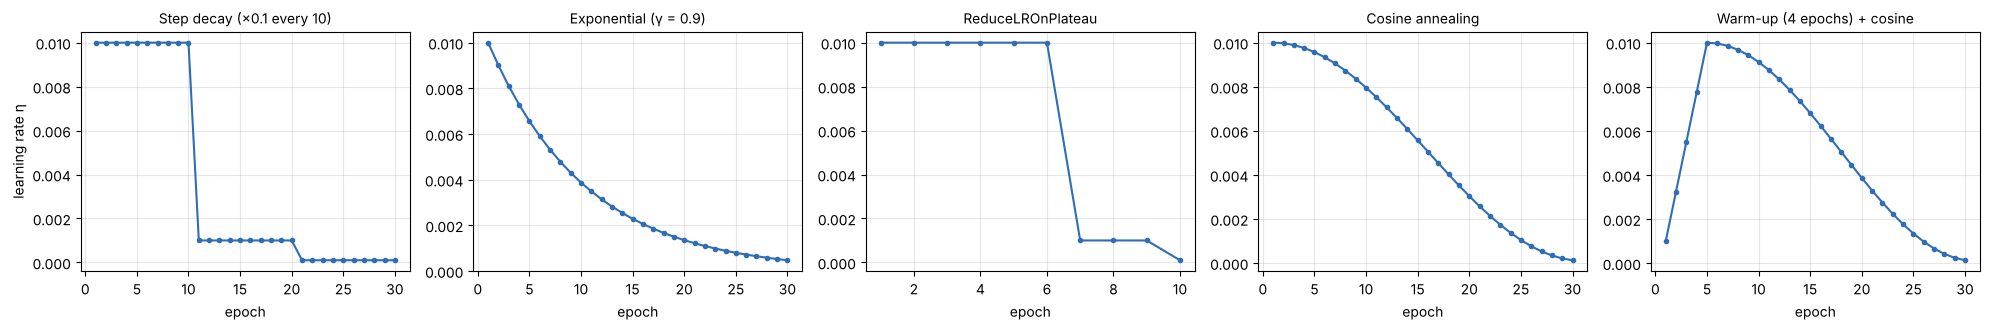

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.4), sharey=False)
for ax, (name, lrs) in zip(axes, [("Step decay (×0.1 every 10)", step_lrs), ("Exponential (γ = 0.9)", exp_lrs),
                                   ("ReduceLROnPlateau", plateau_lrs), ("Cosine annealing", cos_lrs),
                                   ("Warm-up (4 epochs) + cosine", warm_lrs)]):
    ax.plot(range(1, len(lrs) + 1), lrs, "o-", ms=3, color="#2f6db5"); ax.set_title(name, fontsize=10)
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
axes[0].set_ylabel("learning rate η")
plt.tight_layout(); plt.show()

| Schedule | What the numbers show | Pro | Con |
|---|---|---|---|
| **Step decay** | 0.01 for epochs 1–10, 0.001 for 11–20, 0.0001 for 21–30: exactly the lecture's example | simple | you must choose when to cut |
| **Exponential** | η₀·γᵗ: 0.01, 0.009, 0.0081, … (×0.9 each epoch) | smooth | γ must be chosen carefully |
| **ReduceLROnPlateau** | cuts η only when the validation loss stops improving | adapts to the run | needs a validation set; reacts late |
| **Cosine annealing** | a smooth half-cosine from 0.01 down to 0.0001 | smooth, widely used | needs the total length |
| **Warm-up** | starts at 0.001 (10%) and climbs to 0.01 over 4 epochs, then another schedule takes over | avoids early instability | one more setting |

### Does a schedule actually help? A fair test on the digits
Same network (64 → 128 → 10, ReLU), same SGD, same 30 epochs, same seed. A deliberately **high** η = 0.5, constant vs scheduled.

constant η = 0.5                     final training loss 0.01179   test accuracy 97.8% ± 0.2%


step decay (×0.1 at epochs 10, 20)   final training loss 0.04077   test accuracy 97.6% ± 0.2%


cosine annealing                     final training loss 0.02687   test accuracy 97.8% ± 0.1%


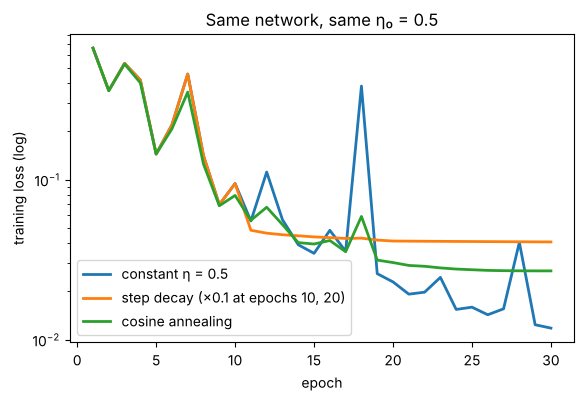

In [6]:
d = load_digits()
Xtr, Xte, ytr, yte = train_test_split(d.data / 16, d.target, test_size=0.3, random_state=0, stratify=d.target)
Xtr, Xte = torch.tensor(Xtr, dtype=torch.float32), torch.tensor(Xte, dtype=torch.float32)
ytr, yte = torch.tensor(ytr), torch.tensor(yte)

def train_with(sched_fn, lr=0.5, epochs=30, seed=0):
    torch.manual_seed(seed)
    net = nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 10))
    opt = torch.optim.SGD(net.parameters(), lr=lr)
    sched = sched_fn(opt) if sched_fn else None
    curve = []
    for ep in range(epochs):
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 32):
            idx = perm[i:i + 32]
            loss = F.cross_entropy(net(Xtr[idx]), ytr[idx]); opt.zero_grad(); loss.backward(); opt.step()
        if sched: sched.step()
        with torch.no_grad():
            curve.append(F.cross_entropy(net(Xtr), ytr).item())
    with torch.no_grad():
        acc = (net(Xte).argmax(1) == yte).float().mean().item()
    return curve, acc

runs = {"constant η = 0.5": None,
        "step decay (×0.1 at epochs 10, 20)": lambda o: S.StepLR(o, 10, 0.1),
        "cosine annealing": lambda o: S.CosineAnnealingLR(o, 30)}
results = {}
for name, fn in runs.items():
    accs, curves = [], []
    for seed in range(3):
        c, a = train_with(fn, seed=seed); accs.append(a); curves.append(c)
    results[name] = np.mean(curves, axis=0)
    print(f"{name:<36} final training loss {np.mean([c[-1] for c in curves]):.5f}   test accuracy {np.mean(accs):.1%} ± {np.std(accs):.1%}")
plt.figure(figsize=(6.5, 4))
for name, c in results.items(): plt.semilogy(range(1, 31), c, lw=2, label=name)
plt.xlabel("epoch"); plt.ylabel("training loss (log)"); plt.legend(); plt.title("Same network, same η₀ = 0.5"); plt.show()

**Honest reading:** on this small, easy problem the schedules made **no real difference**: 97.8% (constant), 97.6% (step decay) and 97.8% (cosine), all within the seed-to-seed spread. The constant-η run even reached the lowest training loss. η = 0.5 happens to be stable for this network, so there was nothing for a schedule to rescue.

Schedules pay off when training is long and the loss surface is sharp: big models, ImageNet-scale data, Transformers (where **warm-up + cosine** is the standard recipe). The lesson is the lecture's: a schedule is a tool to try and **validate**, not a guaranteed win.

## 3 · Saddle points and local minima

### 3a · The classic saddle: f(x, y) = x² − y²
- ∂f/∂x = 2x and ∂f/∂y = −2y, so at (0, 0) **both are 0**: the gradient vanishes.
- Along x (y = 0): f = x², a **minimum** at 0. Along y (x = 0): f = −y², a **maximum** at 0.
- So (0, 0) is neither a minimum nor a maximum: it is a **saddle point** (like a horse's saddle, or a mountain pass).

In [7]:
f = lambda x, y: x ** 2 - y ** 2
print("gradient at (0, 0):", (2 * 0, -2 * 0))
print("along x:", [f(x, 0) for x in [-1, -0.5, 0, 0.5, 1]], "-> minimum at x = 0")
print("along y:", [f(0, y) for y in [-1, -0.5, 0, 0.5, 1]], "-> maximum at y = 0")

gradient at (0, 0): (0, 0)
along x: [1, 0.25, 0, 0.25, 1] -> minimum at x = 0
along y: [-1, -0.25, 0, -0.25, -1] -> maximum at y = 0


Now start **almost exactly** on the saddle's ridge, at (1, 0.001), and count how many steps each optimizer needs to escape (|y| > 1). Same learning rate 0.05 for all three.

plain gradient descent   escaped after 73 steps
momentum (0.9)           escaped after 27 steps
Adam                     escaped after 20 steps


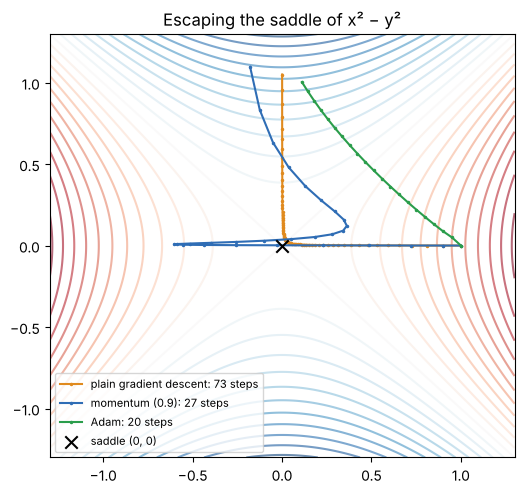

In [8]:
def escape(opt_name, lr=0.05, steps=500):
    p = torch.tensor([1.0, 1e-3], requires_grad=True)
    opt = {"plain gradient descent": torch.optim.SGD([p], lr=lr),
           "momentum (0.9)": torch.optim.SGD([p], lr=lr, momentum=0.9),
           "Adam": torch.optim.Adam([p], lr=lr)}[opt_name]
    path = [p.detach().clone().numpy()]
    for s in range(steps):
        loss = p[0] ** 2 - p[1] ** 2
        opt.zero_grad(); loss.backward(); opt.step()
        path.append(p.detach().clone().numpy())
        if abs(p[1].item()) > 1:
            return s + 1, np.array(path)
    return None, np.array(path)

xs = np.linspace(-1.3, 1.3, 200); GX, GY = np.meshgrid(xs, xs)
plt.figure(figsize=(6, 5.5)); plt.contour(GX, GY, GX ** 2 - GY ** 2, levels=25, cmap="RdBu_r", alpha=0.6)
for name, col in zip(["plain gradient descent", "momentum (0.9)", "Adam"], ["#e08a1e", "#2f6db5", "#2a9d4b"]):
    n, path = escape(name)
    print(f"{name:<24} escaped after {n} steps")
    plt.plot(path[:, 0], path[:, 1], ".-", color=col, ms=3, label=f"{name}: {n} steps")
plt.scatter([0], [0], marker="x", c="k", s=80, zorder=5, label="saddle (0, 0)")
plt.xlim(-1.3, 1.3); plt.ylim(-1.3, 1.3); plt.legend(fontsize=8, loc="lower left"); plt.title("Escaping the saddle of x² − y²"); plt.show()

**Measured:** plain gradient descent needed **73** steps to escape, momentum **27**, Adam **20**.

Why plain GD is slow: near the saddle, y is tiny, so the gradient −2y is tiny too, and y only grows by a factor (1 + 2η) = 1.1 per step. That's the "**optimization can appear stuck**" of the lecture. Momentum accumulates those small pushes into speed. Adam divides each step by the typical gradient size, so even a tiny gradient gives a normal-sized step.

### 3b · Local vs global minimum
L(w) = w⁴ − 3w² + w has **two valleys**: a shallow one (local minimum) and a deeper one (global minimum). Where plain gradient descent ends up depends only on where it starts.

minimum at w = -1.301, L = -3.514
minimum at w = +1.131, L = -1.070
start w = -2.0 -> plain GD ends at w = -1.301 (L = -3.514)   with momentum 0.9 -> w = -1.301
start w = -0.5 -> plain GD ends at w = -1.301 (L = -3.514)   with momentum 0.9 -> w = -1.301
start w = +0.5 -> plain GD ends at w = +1.131 (L = -1.070)   with momentum 0.9 -> w = +1.131
start w = +2.0 -> plain GD ends at w = +1.131 (L = -1.070)   with momentum 0.9 -> w = -1.301


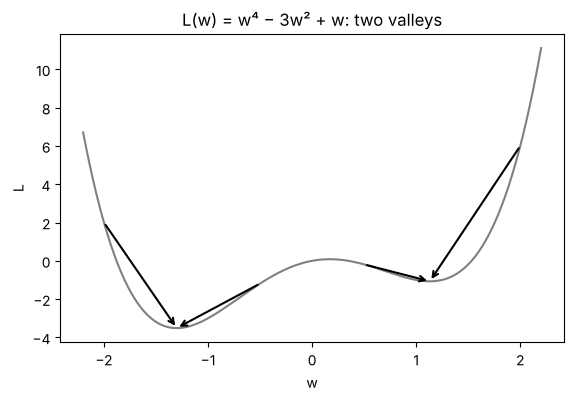

In [9]:
L = lambda w: w ** 4 - 3 * w ** 2 + w
dL = lambda w: 4 * w ** 3 - 6 * w + 1
wg = np.linspace(-2.2, 2.2, 400)
mins = [w for w in np.roots([4, 0, -6, 1]) if 12 * w ** 2 - 6 > 0]
for m in sorted(mins):
    print(f"minimum at w = {m:+.3f}, L = {L(m):+.3f}")

def gd(w, eta=0.01, steps=400, beta=0.0):
    v = 0.0
    for _ in range(steps):
        v = beta * v - eta * dL(w); w = w + v
    return w

plt.figure(figsize=(6.5, 4)); plt.plot(wg, L(wg), color="grey")
for w0 in [-2.0, -0.5, 0.5, 2.0]:
    w_end = gd(w0)
    print(f"start w = {w0:+.1f} -> plain GD ends at w = {w_end:+.3f} (L = {L(w_end):+.3f})   with momentum 0.9 -> w = {gd(w0, beta=0.9):+.3f}")
    plt.annotate("", xy=(w_end, L(w_end)), xytext=(w0, L(w0)), arrowprops=dict(arrowstyle="->", lw=1.5))
plt.title("L(w) = w⁴ − 3w² + w: two valleys"); plt.xlabel("w"); plt.ylabel("L"); plt.show()

- The **global** minimum is at w ≈ −1.301 (L ≈ −3.51); the **local** one at w ≈ +1.131 (L ≈ −1.07). At both, the gradient is 0.
- Plain gradient descent from w = +0.5 or +2.0 ends in the **local** valley and stays there: the gradient is 0, so it has no reason to leave.
- **With momentum (0.9)** from w = +2.0, the built-up speed **carried it over the hump** into the global minimum. (From +0.5 it didn't have enough speed.) Momentum can help, but it's no guarantee.

> **In real networks** (millions of weights), the lecture's point holds: true bad local minima are less of a problem than **saddle points and flat regions**, where the gradient is tiny in most directions. Mini-batch noise, momentum and Adam help to keep moving.

### 3c · Momentum and Adam in one line each
- **Momentum:** v ← β·v − η·g, then w ← w + v. A running "velocity" that **remembers past gradients**, so it keeps rolling through flat stretches and damps zig-zags.
- **Adam:** keeps a running mean of the gradients (m, the momentum-like **first moment**) and of their squares (v, the **second moment**), and steps by m / √v. Directions with tiny gradients get **relatively bigger steps**, which is exactly why it left the saddle fastest.

## 4 · Exploding gradients and gradient clipping

**The lecture's arithmetic:** η = 0.001 and a gradient of 10,000 give an update of 0.001 × 10,000 = **10**: an enormous jump for a weight that is typically around 0.1.

### 4a · Clip by value vs clip by norm (the lecture's examples)

In [10]:
g = torch.tensor([-10.0, -4.0, -1.0, 0.5, 3.0, 8.0])
g_val = g.clamp(-2, 2)
print("original           :", g.tolist())
print("clip by value ±2   :", g_val.tolist())
cos = F.cosine_similarity(g, g_val, dim=0).item()
print(f"direction changed? cosine(original, clipped) = {cos:.3f} (1.000 would mean same direction)")

g2 = torch.tensor([3.0, 4.0]); c = 2.0
norm = g2.norm().item()
g2_clip = g2 * (c / norm) if norm > c else g2
print(f"\ng = {g2.tolist()}: norm = sqrt(3² + 4²) = {norm}")
print(f"clip by norm to c = {c}: g × c/‖g‖ = g × {c / norm} = {[round(v, 4) for v in g2_clip.tolist()]}   new norm {g2_clip.norm().item():.1f}")
print(f"direction kept? cosine = {F.cosine_similarity(g2, g2_clip, dim=0).item():.3f}")

# PyTorch's built-ins do the same thing to a model's gradients
w = torch.zeros(2, requires_grad=True); w.grad = torch.tensor([3.0, 4.0])
total = torch.nn.utils.clip_grad_norm_([w], max_norm=2.0)
print(f"\ntorch.nn.utils.clip_grad_norm_: norm before {total.item():.1f}, gradient after {[round(v, 4) for v in w.grad.tolist()]}")
w2 = torch.zeros(6, requires_grad=True); w2.grad = g.clone()
torch.nn.utils.clip_grad_value_([w2], clip_value=2.0)
print("torch.nn.utils.clip_grad_value_:", w2.grad.tolist())

original           : [-10.0, -4.0, -1.0, 0.5, 3.0, 8.0]
clip by value ±2   : [-2.0, -2.0, -1.0, 0.5, 2.0, 2.0]
direction changed? cosine(original, clipped) = 0.895 (1.000 would mean same direction)

g = [3.0, 4.0]: norm = sqrt(3² + 4²) = 5.0
clip by norm to c = 2.0: g × c/‖g‖ = g × 0.4 = [1.2, 1.6]   new norm 2.0
direction kept? cosine = 1.000

torch.nn.utils.clip_grad_norm_: norm before 5.0, gradient after [1.2, 1.6]
torch.nn.utils.clip_grad_value_: [-2.0, -2.0, -1.0, 0.5, 2.0, 2.0]


- **Clip by value** squashes each component separately: the big ones (−10, 8) are cut much more than the small ones, so the vector now **points in a different direction** (cosine 0.895 < 1).
- **Clip by norm** shrinks the whole vector by one factor (2/5): [3, 4] → **[1.2, 1.6]**. The length becomes 2 and the **direction is unchanged** (cosine 1.000). That's why norm clipping is the usual first choice.

### 4b · A real explosion: a recurrent network
A simple RNN reads 30 numbers one at a time and must output (3 × their average). Its recurrent weights are slightly too large, so gradients **multiply through 30 time steps** and explode. Same network, same data, same SGD (lr 0.01), 400 steps, three ways:

baseline: always predicting the mean gives MSE = Var(y) = 0.320


no clipping            largest gradient norm seen 4.51e+14   final MSE on all data nan


clip by value (±1)     largest gradient norm seen 1.25e+03   final MSE on all data 0.227


clip by norm (max 1)   largest gradient norm seen 733   final MSE on all data 0.04755


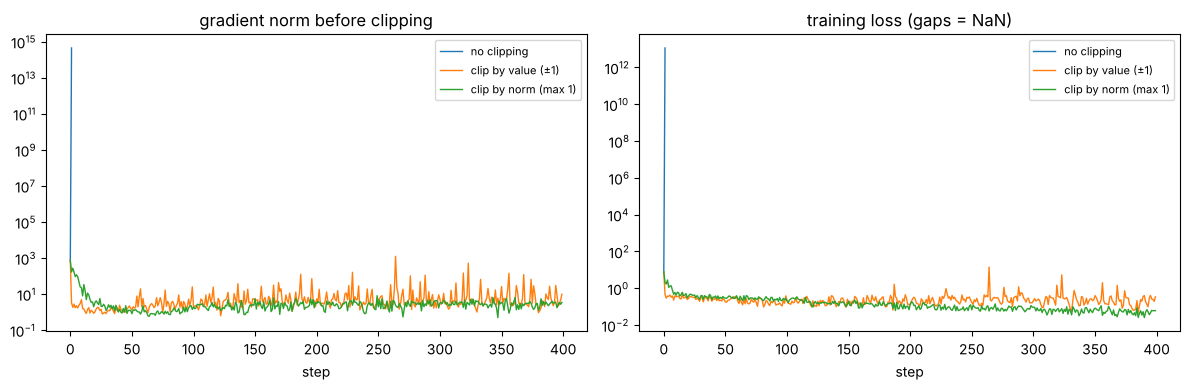

In [11]:
T = 30
gen = torch.Generator().manual_seed(1)
Xs = torch.randn(2048, T, 1, generator=gen); Ys = Xs.mean(1) * 3
print(f"baseline: always predicting the mean gives MSE = Var(y) = {Ys.var().item():.3f}")

def train_rnn(clip):
    torch.manual_seed(0)
    rnn = nn.RNN(1, 32, batch_first=True, nonlinearity="relu"); head = nn.Linear(32, 1)
    nn.init.normal_(rnn.weight_hh_l0, 0, 0.3)          # slightly too large -> exploding gradients
    params = list(rnn.parameters()) + list(head.parameters())
    opt = torch.optim.SGD(params, lr=0.01)
    norms, losses = [], []
    for step in range(400):
        idx = torch.randint(0, 2048, (64,))
        out, _ = rnn(Xs[idx]); loss = F.mse_loss(head(out[:, -1]), Ys[idx])
        opt.zero_grad(); loss.backward()
        norms.append(torch.nn.utils.clip_grad_norm_(params, float("inf")).item())   # just measures the norm
        if clip == "norm": torch.nn.utils.clip_grad_norm_(params, max_norm=1.0)
        if clip == "value": torch.nn.utils.clip_grad_value_(params, clip_value=1.0)
        opt.step(); losses.append(loss.item())
    with torch.no_grad():
        out, _ = rnn(Xs); final = F.mse_loss(head(out[:, -1]), Ys).item()
    return norms, losses, final

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for clip, label in [(None, "no clipping"), ("value", "clip by value (±1)"), ("norm", "clip by norm (max 1)")]:
    norms, losses, final = train_rnn(clip)
    print(f"{label:<22} largest gradient norm seen {max(norms):.3g}   final MSE on all data {final:.4g}")
    axes[0].semilogy(norms, lw=1, label=label); axes[1].semilogy(losses, lw=1, label=label)
axes[0].set_title("gradient norm before clipping"); axes[1].set_title("training loss (gaps = NaN)")
for ax in axes: ax.set_xlabel("step"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Measured:**
- **No clipping:** the gradient norm reached **4.5 × 10¹⁴** and training ended in **NaN**: the classic exploding-gradient failure.
- **Clip by value (±1):** stable, but each component is cut separately, so the update direction is distorted. Final MSE **0.227**, only a little better than predicting the mean (0.320).
- **Clip by norm (max 1):** stable **and** keeps the direction. Final MSE **0.048**, the only run that really learned the task.

That matches the lecture: **norm clipping is the natural first choice**, because it limits the size and keeps the direction.

**In Keras / TensorFlow** (the lecture's code): `keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0)` limits the overall norm; `clipvalue=1.0` clips each component to [−1, 1]. **In PyTorch:** call `torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)` **after** `loss.backward()` and **before** `optimizer.step()`.

### What clipping does **not** fix
It only caps **large** gradients. It does nothing for **vanishing** gradients, a bad architecture, bad initialization, a wrong learning rate, overfitting, underfitting or unnormalised data.

## 5 · How the three ideas fit together

| Symptom | Tool | What it changes |
|---|---|---|
| steps too big/small, or need big-then-small | learning-rate **schedule** | **η** |
| stuck where the gradient ≈ 0 (saddle, plateau) | **momentum, Adam**, mini-batch noise, good init | the **direction/size of steps** using history |
| sudden huge gradients, loss spikes, NaN | gradient **clipping** | the **gradient g** |

**Gradient** = which way is downhill and how steep. **Learning rate** = how far you step. Clipping edits the gradient; a schedule edits η.

## ✅ Check yourself
1. On L(w) = w², which η values converge? *(0 < η < 1; the step multiplies w by 1 − 2η)*
2. Step decay with η₀ = 0.1, γ = 0.5, every 5 epochs: η at epoch 12? *(two cuts: 0.1 × 0.5² = 0.025)*
3. Exponential decay η₀ = 0.01, γ = 0.9: η after 3 epochs? *(0.01 × 0.9³ = 0.00729)*
4. Why warm up? *(early updates from random weights can be huge and unstable; small steps first)*
5. Show that (0, 0) is a saddle of f = x² − y². *(gradient 0; minimum along x, maximum along y)*
6. Clip g = [6, 8] by norm to 5. *(norm 10 → × 0.5 → [3, 4])*
7. Clip g = [6, 8, −1] by value to ±5. *([5, 5, −1]; the direction changes)*
8. Your RNN's loss suddenly becomes NaN. First thing to try? *(gradient clipping by norm, and/or a lower η)*